# Supermarket Vegetable Sales Analysis (2020-2023)
Goal: Help a supermarket manager decide what to order more, what to fix, and what to delete.

Dataset: 878k transactions, 242 products

LOAD AND CLEAN

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('cleaned_sales.csv', parse_dates=['Date'])
# Already cleaned: removed duplicates, fixed dates, calculated Profit = Revenue - Cost
df.head()

,Date,Time,Item Code,Quantity Sold (kilo),Unit Selling Price (RMB/kg),Sale or Return,Discount (Yes/No),Item Name,Category Code,Category Name,Wholesale Price (RMB/kg),Loss Rate (%),Revenue,Cost,Profit,Month,Weekday,Hour
0,2020-07-01,09:15:07.924,102900005117056,0.396,7.6,sale,No,Paopaojiao (Jingpin),1011010504,Capsicum,4.32,7.08,3.0096,1.71072,1.29888,2020-07,Wednesday,9
1,2020-07-01,09:17:27.295,102900005115960,0.849,3.2,sale,No,Chinese Cabbage,1011010101,Flower/Leaf Vegetables,2.10,22.27,2.7168,1.78290,0.93390,2020-07,Wednesday,9
2,2020-07-01,09:17:33.905,102900005117056,0.409,7.6,sale,No,Paopaojiao (Jingpin),1011010504,Capsicum,4.32,7.08,3.1084,1.76688,1.34152,2020-07,Wednesday,9
3,2020-07-01,09:19:45.450,102900005115823,0.421,10.0,sale,No,Shanghaiqing,1011010101,Flower/Leaf Vegetables,7.03,14.43,4.2100,2.95963,1.25037,2020-07,Wednesday,9
4,2020-07-01,09:20:23.686,102900005115908,0.539,8.0,sale,No,Caixin,1011010101,Flower/Leaf Vegetables,4.60,13.70,4.3120,2.47940,1.83260,2020-07,Wednesday,9


YEARLY HEALTH

In [7]:
df['Year'] = df['Date'].dt.year
yearly = df.groupby('Year')[['Revenue','Profit','Quantity Sold (kilo)']].sum()
yearly['Margin'] = yearly['Profit'] / yearly['Revenue'] * 100
yearly

,Revenue,Profit,Quantity Sold (kilo),Margin
Year,,,,
2020,6.704925e+05,248855.18892,86681.649,37.115284
2021,1.101976e+06,390477.49086,137627.167,35.434286
2022,1.037926e+06,398648.65055,161499.327,38.408196
2023,5.638853e+05,207512.46417,85767.617,36.800476


MONTHLY SEASONALITY CHART

<Axes: title={'center': 'Monthly Revenue vs Profit - Clear CNY Spike Every January'}, xlabel='Month'>

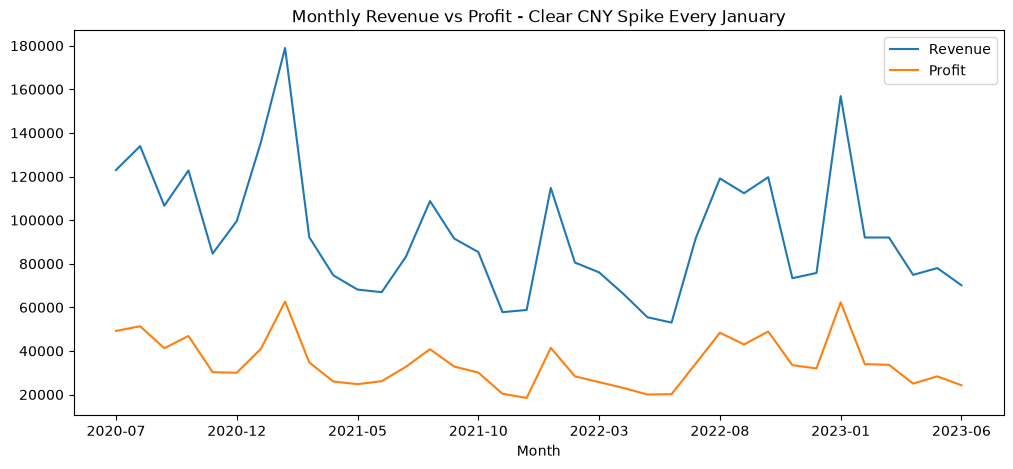

In [8]:
monthly = df.groupby('Month')[['Revenue','Profit']].sum()
monthly.plot(figsize=(12,5), title='Monthly Revenue vs Profit - Clear CNY Spike Every January')

TOP PRODUCTS

In [9]:
summary = df.groupby('Item Name').agg(
    Total_Profit=('Profit','sum'),
    Total_Revenue=('Revenue','sum'),
    Loss_Rate=('Loss Rate (%)','first')
).sort_values('Total_Profit', ascending=False)
summary.head(10)

,Total_Profit,Total_Revenue,Loss_Rate
Item Name,,,
Broccoli,90256.80361,270253.5740,9.26
Xixia Mushroom (1),71574.02959,211515.0532,13.82
Net Lotus Root (1),62412.56489,211887.7781,5.54
Wuhu Green Pepper (1),61455.14920,205326.1779,5.70
Yunnan Shengcai,50006.38478,129837.1735,15.25
Eggplant (2),40174.33925,117865.6355,6.07
Luosi Pepper,28203.40096,82054.5191,10.18
Yunnan Lettuces,27912.29039,70719.3961,12.81
Millet Pepper (Bag),27389.43000,55144.6000,9.43


DECISION ENGINE

In [10]:
def decision(row):
    if row['Loss_Rate'] > 25 and row['Total_Profit'] < 1000:
        return 'DELETE'
    elif row['Loss_Rate'] > 20 and row['Total_Profit'] > 3000:
        return 'KEEP BUT FIX STORAGE'
    elif row['Total_Profit'] > 20000:
        return 'STAR - Order more'
    else:
        return 'KEEP - Normal'

summary['Decision'] = summary.apply(decision, axis=1)
summary['Decision'].value_counts()
summary[summary['Decision'] == 'DELETE']
summary[summary['Decision'] == 'KEEP BUT FIX STORAGE']

,Total_Profit,Total_Revenue,Loss_Rate,Decision
Item Name,,,,
Chinese Cabbage,25895.91737,65783.8618,22.27,KEEP BUT FIX STORAGE
Honghu Lotus Root,6809.68263,21463.0442,24.05,KEEP BUT FIX STORAGE
High Melon (1),6601.14879,16275.7631,29.25,KEEP BUT FIX STORAGE
Foreign Garland Chrysanthemum,4458.19597,11699.6930,26.16,KEEP BUT FIX STORAGE
Dongmenkou Xiaobaicai,3244.35709,8016.0542,27.84,KEEP BUT FIX STORAGE


Conclusion: Business is stable + seasonal. 17 Stars, 5 to fix, 2 to delete. 

Biggest win: Fix storage for Chinese Cabbage (loses 5,767 RMB to waste) and stock up for Chinese New Year.